<div dir="rtl">

# پروژه‌ی ۳ — راه‌حل مرجع (فقط برای مدرس)

یک پیاده‌سازی از الزامات اصلی، برای مقایسه با گزارش‌ها و طرح سؤال در دفاع. تصمیم‌های پاک‌سازی (مثلاً میانگین گرفتن از دو سطر متناقض، حد ۶ ساعت برای حسگر گیرکرده، یا ضرب کردن مقدارهای ماه اکتبر ایستگاه حومه در ۱۰۰۰) قابل بحث‌اند؛ دانشجو می‌تواند تصمیم دیگری بگیرد، به شرط آنکه آن را توضیح دهد. داده با <code dir="ltr">s30&#95;gen&#95;data.py</code> ساخته شده است. در این پیاده‌سازی، برای سادگی، شبکه‌ی ساعتی به سال ۲۰۲۵ وابسته است؛ از دانشجو کد عمومی خواسته شده است.

### حقیقت پنهان داده (برای مدرس)

- <code dir="ltr">PM2.5</code> در زمستان بسیار بیشتر است (دوره‌های پایداری هوا با باد کم): میانگین ماهانه‌ی شهر از حدود ۲۵ در تیر تا حدود ۹۰ در دی.
- باد و باران آلودگی را کم می‌کنند (همبستگی <code dir="ltr">PM2.5</code> با باد حدود منفی ۰٫۸)؛ روز بعد از باران شدید هوا پاک‌تر است.
- <code dir="ltr">NO2</code> الگوی ترافیک دارد: اوج ساعت ۸ و ۱۹، کمینه حدود ساعت ۳ و ۱۴؛ جمعه حدود ۲۵٪ کمتر. <code dir="ltr">PM2.5</code> در جمعه فقط حدود ۱۰٪ کمتر است.
- ایستگاه صنعتی (<code dir="ltr">ST02</code>) بیشترین <code dir="ltr">PM2.5</code> و ایستگاه مرکز (<code dir="ltr">ST01</code>) بیشترین <code dir="ltr">NO2</code> را دارد؛ حومه (<code dir="ltr">ST04</code>) پاک‌ترین است. همبستگی روزانه‌ی ایستگاه‌ها حدود ۰٫۹ است: عامل اصلی، هواشناسی سراسری شهر است.
- **تعطیلی‌ها:** ۱۲ روز، وقتی آلودگی روز قبل شهر از حد معینی بالاتر بوده اعلام شده‌اند. اثر واقعی تعطیلی در داده: <code dir="ltr">NO2</code> حدود ۲۰٪ و <code dir="ltr">PM2.5</code> حدود ۷٪ کمتر. مقایسه‌ی ساده روزهای تعطیلی را **آلوده‌تر** نشان می‌دهد (اثر انتخاب).

### ایرادهای کاشته‌شده

| ایراد | جزئیات |
|---|---|
| ایستگاه با کد ناهمسان | <code dir="ltr">st-02</code> در اسفند/مارس برای <code dir="ltr">ST02</code>؛ در <code dir="ltr">stations.csv</code> یک کد با فاصله (<code dir="ltr"> ST03</code>) و یک ایستگاه برچیده‌شده (<code dir="ltr">ST05</code>) بدون داده |
| عدد با ویرگول اعشار | <code dir="ltr">PM2.5</code> ایستگاه <code dir="ltr">ST02</code> در ماه مارس |
| تاریخ با <code dir="ltr">/</code> | ایستگاه <code dir="ltr">ST03</code> در ماه مه |
| کد قراردادی <code dir="ltr">-999</code> | ۳۵۰ مقدار <code dir="ltr">PM2.5</code> و ۲۰۰ مقدار <code dir="ltr">NO2</code> |
| مقدار منفی و ناممکن | ۱۲ مقدار <code dir="ltr">-3.0</code> و ۶ مقدار <code dir="ltr">9999</code> در <code dir="ltr">PM2.5</code> |
| خانه‌ی خالی | ۴۰ مقدار <code dir="ltr">NO2</code> |
| سطر تکراری | ۶۰ تکرار یکسان و ۸ تکرار با <code dir="ltr">NO2</code> متفاوت |
| ساعت‌های ثبت‌نشده | ایستگاه <code dir="ltr">ST01</code> از ۱ تا ۱۴ آوریل خاموش (سطرها وجود ندارند) |
| حسگر گیرکرده | <code dir="ltr">PM2.5</code> ایستگاه <code dir="ltr">ST03</code> از ۱۰ تا ۱۳ ژوئیه ثابت روی <code dir="ltr">41.0</code> |
| واحد اشتباه | <code dir="ltr">PM2.5</code> ایستگاه <code dir="ltr">ST04</code> در اکتبر به میلی‌گرم (۱۰۰۰ برابر کوچک‌تر) |
| هواشناسی | باران صفر به‌صورت خانه‌ی خالی، یک روز تکراری، یک روز گمشده |
| تعطیلی‌ها | بعضی تاریخ‌ها بدون صفر اول (<code dir="ltr">2025-1-8</code>) |

</div>

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


BREAKS = [0, 12, 35.5, 55.5, 150.5, 250.5, np.inf]
LABELS = ["good", "moderate", "unhealthy_sensitive", "unhealthy", "very_unhealthy", "hazardous"]


def load_raw(folder):
    folder = Path(folder)
    with open(folder / "closures.json", encoding="utf-8") as f:
        closures = pd.DataFrame(json.load(f)["closures"])
    return {
        "air_quality": pd.read_csv(folder / "air_quality.csv", dtype=str),
        "stations": pd.read_csv(folder / "stations.csv", dtype=str),
        "weather": pd.read_csv(folder / "weather.csv"),
        "closures": closures,
    }


def fix_station(code):
    code = str(code).strip().upper().replace("-", "").replace(" ", "")
    return code


def clean_air(air, stations):
    issues = []
    df = air.copy()
    n0 = len(df)
    df["station"] = df["station"].map(fix_station)
    valid = set(stations["station_id"].map(fix_station))
    bad = ~df["station"].isin(valid)
    issues.append(("unknown station", int(bad.sum())))
    df = df[~bad]

    df["datetime"] = pd.to_datetime(df["datetime"].str.replace("/", "-", regex=False), format="%Y-%m-%d %H:%M")
    for col in ["pm25", "no2"]:
        df[col] = pd.to_numeric(df[col].str.replace(",", ".", regex=False), errors="coerce")

    exact = df.duplicated()
    issues.append(("exact duplicate rows", int(exact.sum())))
    df = df[~exact]
    conflict = df.duplicated(["station", "datetime"], keep=False)
    issues.append(("conflicting duplicates (rows)", int(conflict.sum())))
    df = (df.groupby(["station", "datetime"], as_index=False)[["pm25", "no2"]].mean())

    for col in ["pm25", "no2"]:
        sent = df[col] == -999
        issues.append((f"{col}: -999 sentinel", int(sent.sum())))
        df.loc[sent, col] = np.nan
        neg = df[col] < 0
        issues.append((f"{col}: negative", int(neg.sum())))
        df.loc[neg, col] = np.nan
        huge = df[col] > 1000
        issues.append((f"{col}: > 1000 (impossible)", int(huge.sum())))
        df.loc[huge, col] = np.nan
        issues.append((f"{col}: empty", int(df[col].isna().sum())))

    # unit change: monthly median far below 1 means mg/m3
    month = df["datetime"].dt.to_period("M")
    med = df.groupby([df["station"], month])["pm25"].transform("median")
    mg = med < 1
    issues.append(("pm25 in mg/m3 (x1000)", int(mg.sum())))
    df.loc[mg, "pm25"] = df.loc[mg, "pm25"] * 1000

    # flatline: same value for >= 6 consecutive hours
    df = df.sort_values(["station", "datetime"]).reset_index(drop=True)
    flat = np.zeros(len(df), bool)
    for sid, g in df.groupby("station"):
        v = g["pm25"]
        run_id = (v != v.shift()).cumsum()
        run_len = v.groupby(run_id).transform("size")
        flat[g.index[(run_len >= 6) & v.notna()]] = True
    issues.append(("pm25 flatline >= 6 h", int(flat.sum())))
    df.loc[flat, "pm25"] = np.nan

    # complete the hourly grid so missing hours are explicit
    full = pd.MultiIndex.from_product([sorted(df["station"].unique()),
                                       pd.date_range("2025-01-01", "2025-12-31 23:00", freq="h")],
                                      names=["station", "datetime"])
    before = len(df)
    df = df.set_index(["station", "datetime"]).reindex(full).reset_index()
    issues.append(("missing hourly rows added as NaN", len(df) - before))
    issues.insert(0, ("raw rows", n0))
    return df, pd.DataFrame(issues, columns=["issue", "count"])


def daily_summary(hourly, min_hours=18):
    h = hourly.copy()
    h["date"] = h["datetime"].dt.normalize()
    g = h.groupby(["station", "date"])
    d = g.agg(pm25_mean=("pm25", "mean"), no2_mean=("no2", "mean"), n_valid_hours=("pm25", "count")).reset_index()
    d.loc[d["n_valid_hours"] < min_hours, ["pm25_mean"]] = np.nan
    d["category"] = pd.cut(d["pm25_mean"], BREAKS, labels=LABELS, right=False)
    return d


def clean_weather(w):
    w = w.drop_duplicates("date").copy()
    w["date"] = pd.to_datetime(w["date"])
    w["rain_mm"] = w["rain_mm"].fillna(0.0)
    return w.set_index("date").reindex(pd.date_range("2025-01-01", "2025-12-31")).rename_axis("date").reset_index()


def clean_closures(c):
    c = c.copy()
    c["date"] = pd.to_datetime(c["date"], format="mixed")
    return c

In [2]:
raw = load_raw("data/air")
hourly, issues = clean_air(raw["air_quality"], raw["stations"])
print(issues.to_string())
daily = daily_summary(hourly)
print("unknown days:", daily.pm25_mean.isna().groupby(daily.station).sum().to_dict())
print("annual PM2.5:", daily.groupby("station").pm25_mean.mean().round(1).to_dict())
print("annual NO2:", daily.groupby("station").no2_mean.mean().round(1).to_dict())

                               issue  count
0                           raw rows  34772
1                    unknown station      0
2               exact duplicate rows     60
3      conflicting duplicates (rows)     16
4                pm25: -999 sentinel    350
5                     pm25: negative     12
6          pm25: > 1000 (impossible)      6
7                        pm25: empty    368
8                 no2: -999 sentinel    200
9                      no2: negative      0
10          no2: > 1000 (impossible)      0
11                        no2: empty    240
12             pm25 in mg/m3 (x1000)    744
13              pm25 flatline >= 6 h     82
14  missing hourly rows added as NaN    336
unknown days: {'ST01': 14, 'ST02': 0, 'ST03': 4, 'ST04': 0}
annual PM2.5: {'ST01': 55.7, 'ST02': 74.5, 'ST03': 48.3, 'ST04': 30.5}
annual NO2: {'ST01': 58.7, 'ST02': 43.9, 'ST03': 36.4, 'ST04': 17.0}


In [3]:
city = daily.groupby("date")[["pm25_mean", "no2_mean"]].mean()
city["category"] = pd.cut(city.pm25_mean, BREAKS, labels=LABELS, right=False)
print(city.category.value_counts().reindex(LABELS).to_dict())
print(city.pm25_mean.nlargest(10).round(1))
print("monthly:", city.pm25_mean.groupby(city.index.month).mean().round(0).to_dict())

{'good': 2, 'moderate': 133, 'unhealthy_sensitive': 95, 'unhealthy': 133, 'very_unhealthy': 2, 'hazardous': 0}
date
2025-12-05    183.0
2025-01-28    158.7
2025-02-06    150.2
2025-02-03    146.6
2025-12-30    143.0
2025-01-03    142.5
2025-12-29    142.3
2025-12-14    142.3
2025-01-11    139.8
2025-01-27    138.8
Name: pm25_mean, dtype: float64
monthly: {1: 84.0, 2: 74.0, 3: 57.0, 4: 49.0, 5: 32.0, 6: 25.0, 7: 29.0, 8: 29.0, 9: 47.0, 10: 47.0, 11: 64.0, 12: 91.0}


In [4]:
h = hourly.assign(hour=hourly.datetime.dt.hour, friday=hourly.datetime.dt.dayofweek == 4)
prof = h.groupby(["friday", "hour"])[["pm25", "no2"]].mean().round(1)
print(prof.unstack(0).iloc[[3, 8, 14, 19, 21]])
print(h.groupby("friday")[["pm25", "no2"]].mean().round(1))

        pm25         no2      
friday False True  False True 
hour                          
3       50.0  45.1  21.9  17.0
8       61.8  57.0  63.0  48.5
14      40.8  38.2  34.4  26.2
19      57.5  54.4  58.2  45.4
21      67.4  60.2  45.0  34.7
        pm25   no2
friday            
False   52.9  40.2
True    48.3  30.8


In [5]:
w = clean_weather(raw["weather"])
m = city.reset_index().merge(w, on="date", how="left")
print(m[["pm25_mean", "no2_mean", "wind_ms", "rain_mm", "temp_c", "humidity"]].corr().loc[["pm25_mean", "no2_mean"]].round(2))
m["heavy_rain_yesterday"] = m.rain_mm.shift(1) > 5
print(m.groupby("heavy_rain_yesterday").pm25_mean.mean().round(1))
print(daily.pivot(index="date", columns="station", values="pm25_mean").corr().round(2))

           pm25_mean  no2_mean  wind_ms  rain_mm  temp_c  humidity
pm25_mean       1.00      0.87    -0.79    -0.17   -0.66      0.43
no2_mean        0.87      1.00    -0.69    -0.14   -0.58      0.38
heavy_rain_yesterday
False    52.7
True     44.7
Name: pm25_mean, dtype: float64
station  ST01  ST02  ST03  ST04
station                        
ST01     1.00  0.91  0.93  0.91
ST02     0.91  1.00  0.91  0.92
ST03     0.93  0.91  1.00  0.93
ST04     0.91  0.92  0.93  1.00


In [6]:
c = clean_closures(raw["closures"])
m["closure"] = m.date.isin(c.date)
print("naive:")
print(m.groupby("closure")[["pm25_mean", "no2_mean"]].mean().round(1))
m["prev_pm"] = m.pm25_mean.shift(1)
m["ratio_pm"] = m.pm25_mean / m.prev_pm
m["ratio_no2"] = m.no2_mean / m.no2_mean.shift(1)
high = m[(m.prev_pm > 110) & (m.date.dt.dayofweek != 4)]
print("days after a day with city PM2.5 > 110 (not Friday):", high.closure.value_counts().to_dict())
print(high.groupby("closure")[["pm25_mean", "no2_mean", "prev_pm", "wind_ms", "ratio_pm", "ratio_no2"]].mean().round(3))

naive:
         pm25_mean  no2_mean
closure                     
False         50.9      38.6
True          93.7      43.2
days after a day with city PM2.5 > 110 (not Friday): {True: 12, False: 5}
         pm25_mean  no2_mean  prev_pm  wind_ms  ratio_pm  ratio_no2
closure                                                            
False       87.606    51.477  116.027    2.520     0.755      0.876
True        93.664    43.151  144.548    2.283     0.659      0.697


<div dir="rtl">

نتیجه‌ی مورد انتظار: مقایسه‌ی ساده (حدود ۹۴ در برابر ۵۱) گمراه‌کننده است. در مقایسه با روزهای مشابه (روز قبل آلوده، غیرجمعه)، کاهش نسبت به روز قبل برای <code dir="ltr">NO2</code> آشکارتر است (حدود ۰٫۷۰ در برابر ۰٫۸۸) تا برای <code dir="ltr">PM2.5</code> (حدود ۰٫۶۶ در برابر ۰٫۷۶). تعداد روزهای کنترل کم است (۵ روز)؛ نتیجه‌گیری قطعی ممکن نیست و بخشی از بهبود به تغییر هوا مربوط است.

</div>

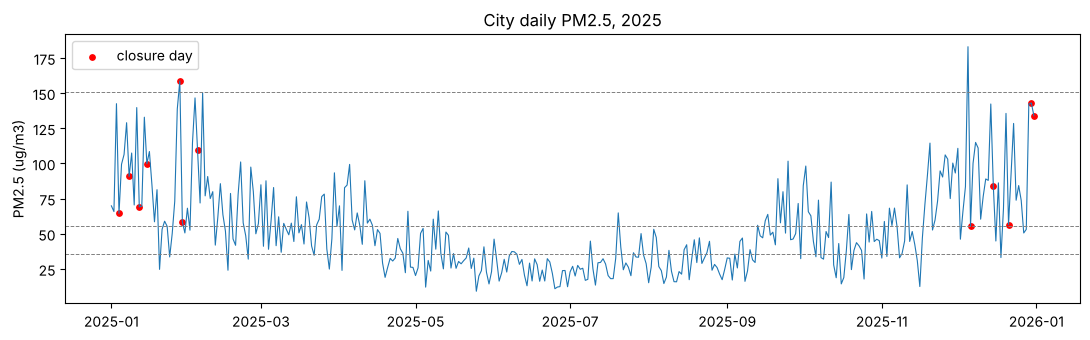

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(city.index, city.pm25_mean, lw=0.8)
for b in [35.5, 55.5, 150.5]:
    ax.axhline(b, ls="--", lw=0.7, color="gray")
ax.scatter(c.date, city.reindex(c.date).pm25_mean, color="red", s=15, label="closure day")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("City daily PM2.5, 2025"); ax.legend()
plt.tight_layout(); plt.show()